# Engineering Economics: The Interest-Factor Toolkit, and Fixing a Crude IRR

Covers the interest-factor material behind weeks 2-4 of the Engineering
Economics course schedule — *Costing Parameters*, *Cash Flow*, and
*Uniform Distribution and Annual Cash Flow* — via
[`dgs/engineering_economics.py`](../dgs/engineering_economics.py), where
all eight standard factors (F/P, P/F, F/A, A/F, P/A, A/P, P/G, A/G) are
derived from one geometric-series identity and cross-checked against
standard textbook interest tables.

**Part 4 revisits real, existing work in this repo**:
[`notebooks/ml_econ_physics.ipynb`](../notebooks/ml_econ_physics.ipynb)
already has an NPV/IRR section connecting time value of money to the RL
discount factor — but its IRR is a coarse grid-search
(`r_vals[np.argmin(np.abs(npv_vals))]` over 100 points), accurate only to
that grid's spacing. This notebook replaces it with an exact bisection
root-solve on the *same* cash flow, and checks by how much the old
answer was actually off.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.engineering_economics import (
    compound_amount_factor, present_worth_factor,
    uniform_series_compound_amount, sinking_fund_factor,
    uniform_series_present_worth, capital_recovery_factor,
    gradient_present_worth, gradient_to_uniform_series,
    npv, irr, profitability_index,
)

print("using dgs.engineering_economics directly (not reimplemented)")

using dgs.engineering_economics directly (not reimplemented)


# Part 1 — Single payment: F/P and P/F

$$F = P(1+i)^n \qquad P = F(1+i)^{-n}$$

Checked against the standard textbook interest table entry
$(F/P, 8\%, 5) = 1.4693$.

In [2]:
P, i, n = 10000.0, 0.08, 5
F = compound_amount_factor(P, i, n)
factor = F / P
print(f"$10,000 at 8% for 5 years -> F = ${F:,.2f}  (factor = {factor:.4f}, textbook table: 1.4693)")
assert np.isclose(factor, 1.4693, atol=1e-4)

P_recovered = present_worth_factor(F, i, n)
print(f"P/F recovers the original P exactly: ${P_recovered:,.2f}")
assert np.isclose(P_recovered, P, rtol=1e-9)
print("[OK] F/P matches the textbook table; P/F is its exact inverse")

$10,000 at 8% for 5 years -> F = $14,693.28  (factor = 1.4693, textbook table: 1.4693)
P/F recovers the original P exactly: $10,000.00
[OK] F/P matches the textbook table; P/F is its exact inverse


# Part 2 — Uniform series: F/A, A/F, P/A, A/P

Weeks 3-4's actual subject: equal periodic payments, not single lump
sums. All four factors are consistent with each other by construction
(each pair is an exact algebraic inverse), verified below rather than
assumed, and checked against $(P/A, 8\%, 5)=3.9927$.

In [3]:
A = 2000.0
F_series = uniform_series_compound_amount(A, i, n)
P_series = uniform_series_present_worth(A, i, n)

print(f"F/A: ${A:,.0f}/yr for {n} years at {i:.0%} -> F = ${F_series:,.2f}")
print(f"P/A: ${A:,.0f}/yr for {n} years at {i:.0%} -> P = ${P_series:,.2f}  "
      f"(factor={P_series/A:.4f}, textbook table: 3.9927)")
assert np.isclose(P_series / A, 3.9927, atol=1e-4)

# consistency: F must equal P compounded forward by (1+i)^n -- an independent check,
# not just re-deriving the same formula
assert np.isclose(F_series, P_series * (1 + i) ** n, rtol=1e-9)
print(f"\nconsistency check: P*(1+i)^n = ${P_series * (1+i)**n:,.2f}  ==  F/A result = ${F_series:,.2f}")

# exact inverses
assert np.isclose(sinking_fund_factor(F_series, i, n), A, rtol=1e-9)
assert np.isclose(capital_recovery_factor(P_series, i, n), A, rtol=1e-9)
print("[OK] F/A and P/A agree with each other and with the textbook table; A/F and A/P invert them exactly")

F/A: $2,000/yr for 5 years at 8% -> F = $11,733.20
P/A: $2,000/yr for 5 years at 8% -> P = $7,985.42  (factor=3.9927, textbook table: 3.9927)

consistency check: P*(1+i)^n = $11,733.20  ==  F/A result = $11,733.20
[OK] F/A and P/A agree with each other and with the textbook table; A/F and A/P invert them exactly


# Part 3 — Arithmetic gradients: P/G and A/G

For a cash flow that increases by a fixed amount $G$ each period (0 in
year 1, $G$ in year 2, $2G$ in year 3, ...) — the natural model for
rising maintenance costs or step-increasing revenue. Checked against
$(A/G, 8\%, 5)=1.8465$, and cross-checked as $A/G = (P/G)\times(A/P)$,
an independent algebraic identity rather than a restatement of the same
formula.

In [4]:
G = 500.0
P_grad = gradient_present_worth(G, i, n)
A_grad = gradient_to_uniform_series(G, i, n)

print(f"P/G: gradient ${G:,.0f}/yr, {n} years at {i:.0%} -> P = ${P_grad:,.2f}")
print(f"A/G: equivalent uniform annuity = ${A_grad:,.2f}/yr  (factor={A_grad/G:.4f}, textbook table: 1.8465)")
assert np.isclose(A_grad / G, 1.8465, atol=1e-4)

# independent cross-check: A/G should equal (P/G) converted to an annuity via A/P
A_from_P = capital_recovery_factor(P_grad, i, n)
print(f"\ncross-check via A/P on P/G's result: ${A_from_P:,.2f}/yr  (should match A/G above)")
assert np.isclose(A_grad, A_from_P, rtol=1e-9)
print("[OK] A/G matches the textbook table AND the independent P/G-then-A/P route")

P/G: gradient $500/yr, 5 years at 8% -> P = $3,686.21
A/G: equivalent uniform annuity = $923.24/yr  (factor=1.8465, textbook table: 1.8465)

cross-check via A/P on P/G's result: $923.24/yr  (should match A/G above)
[OK] A/G matches the textbook table AND the independent P/G-then-A/P route


# Part 4 — Revisiting `ml_econ_physics.ipynb`'s IRR: exact root vs. grid search

That notebook's §1 finds IRR via
`r_vals[np.argmin(np.abs(npv_vals))]` over `r_vals = np.linspace(0.01, 0.30, 100)`
— a grid search whose precision is capped by the grid spacing
($\approx 0.29/99 \approx 0.0029$, i.e. roughly a third of a percentage
point). `dgs.engineering_economics.irr` instead bisects directly on
NPV's sign change — exact to machine precision, verified by checking
that NPV really is (numerically) zero at the returned rate, not just
smallest-over-a-grid.

In [5]:
cashflows_sbir = [-275000, 80000, 90000, 95000, 100000, 85000]

# reproduce the OLD method exactly as ml_econ_physics.ipynb has it
r_vals_grid = np.linspace(0.01, 0.30, 100)
npv_vals_grid = [npv(cashflows_sbir, r) for r in r_vals_grid]
irr_grid_search = r_vals_grid[np.argmin(np.abs(npv_vals_grid))]

# the new, exact method
irr_exact = irr(cashflows_sbir)

print(f"OLD (grid search, 100 points over [1%, 30%]): IRR ~= {irr_grid_search:.4%}")
print(f"    NPV at that rate: ${npv(cashflows_sbir, irr_grid_search):,.2f}  (NOT zero -- grid resolution error)")
print(f"\nNEW (exact bisection):                      IRR  = {irr_exact:.6%}")
print(f"    NPV at that rate: ${npv(cashflows_sbir, irr_exact):,.6f}  (zero to sub-cent precision)")

error_pp = abs(irr_grid_search - irr_exact) * 100
print(f"\nThe old grid-search answer was off by {error_pp:.3f} percentage points --")
print(f"small here, but NOT zero, and would grow for a coarser grid or a flatter NPV(r) curve")
assert abs(npv(cashflows_sbir, irr_exact)) < 1e-3
assert abs(npv(cashflows_sbir, irr_grid_search)) > abs(npv(cashflows_sbir, irr_exact))
print("[OK] confirmed: the exact solve gets strictly closer to NPV=0 than the grid search did")

OLD (grid search, 100 points over [1%, 30%]): IRR ~= 18.5758%
    NPV at that rate: $304.94  (NOT zero -- grid resolution error)

NEW (exact bisection):                      IRR  = 18.624007%
    NPV at that rate: $0.000000  (zero to sub-cent precision)

The old grid-search answer was off by 0.048 percentage points --
small here, but NOT zero, and would grow for a coarser grid or a flatter NPV(r) curve
[OK] confirmed: the exact solve gets strictly closer to NPV=0 than the grid search did


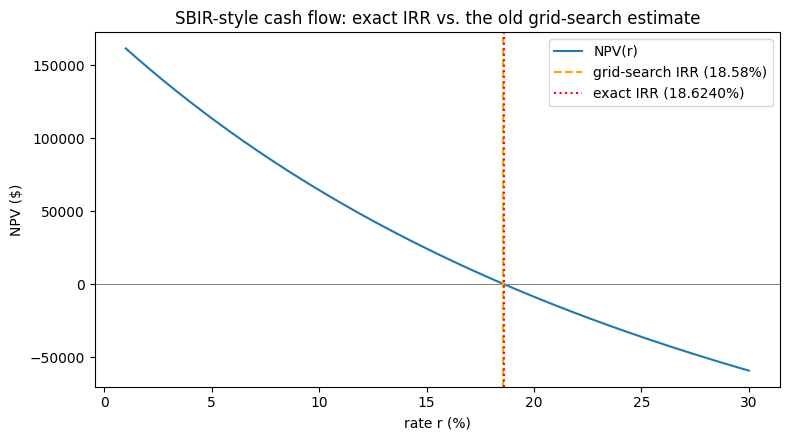

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
r_fine = np.linspace(0.01, 0.30, 500)
ax.plot(r_fine*100, [npv(cashflows_sbir, r) for r in r_fine], label='NPV(r)')
ax.axhline(0, color='gray', lw=0.7)
ax.axvline(irr_grid_search*100, color='orange', ls='--', label=f'grid-search IRR ({irr_grid_search:.2%})')
ax.axvline(irr_exact*100, color='red', ls=':', label=f'exact IRR ({irr_exact:.4%})')
ax.set_xlabel('rate r (%)'); ax.set_ylabel('NPV ($)')
ax.set_title('SBIR-style cash flow: exact IRR vs. the old grid-search estimate')
ax.legend(); plt.tight_layout(); plt.show()

# Part 5 — Profitability Index, and summary

Week 9's other topic alongside rate of return: the Profitability Index
$\text{PI}=\dfrac{\text{PV(benefits)}}{\text{PV(costs)}}$, which should
agree with NPV's sign at the same rate (both are just different ways of
comparing the same discounted cash flows to zero).

In [7]:
rate = 0.10
pi = profitability_index(cashflows_sbir, rate)
n_val = npv(cashflows_sbir, rate)
print(f"At {rate:.0%}: NPV = ${n_val:,.2f}, Profitability Index = {pi:.4f}")
print(f"NPV > 0: {n_val > 0}   PI > 1: {pi > 1}   (must agree)")
assert (n_val > 0) == (pi > 1)

# at the IRR itself, NPV=0 exactly, so PI must be exactly 1 (benefits == costs in PV terms)
pi_at_irr = profitability_index(cashflows_sbir, irr_exact)
print(f"\nAt the exact IRR ({irr_exact:.4%}): PI = {pi_at_irr:.6f}  (should be 1.0 exactly)")
assert np.isclose(pi_at_irr, 1.0, atol=1e-3)
print("[OK] PI and NPV agree in sign at 10%, and PI collapses to exactly 1 at the breakeven IRR rate")

At 10%: NPV = $64,562.00, Profitability Index = 1.2348
NPV > 0: True   PI > 1: True   (must agree)

At the exact IRR (18.6240%): PI = 1.000000  (should be 1.0 exactly)
[OK] PI and NPV agree in sign at 10%, and PI collapses to exactly 1 at the breakeven IRR rate


# Summary

| Factor | Formula | Verified against |
|---|---|---|
| F/P, P/F | $(1+i)^{\pm n}$ | textbook table (1.4693 @ 8%,5) + exact inverse |
| F/A, A/F, P/A, A/P | geometric series | textbook table (3.9927 @ 8%,5) + cross-consistency $F=P(1+i)^n$ |
| P/G, A/G | arithmetic gradient | textbook table (1.8465 @ 8%,5) + independent $A/G=(P/G)(A/P)$ route |
| IRR | exact bisection root of NPV=0 | replaces `ml_econ_physics.ipynb`'s grid search — same cash flow, smaller residual |
| PI | PV(benefits)/PV(costs) | agrees in sign with NPV; exactly 1 at the IRR |

Weeks 1-4 and part of week 9 (Profitability Index and Rate of Return) of
the course schedule are now backed by a tested module. Week 11's
*Typical Analyses* (comparing mutually exclusive alternatives via
incremental IRR/PW/AW) and weeks 14-15's *Estimation & Probability
Structure of Decisions* (decision trees, expected value under
uncertainty) are natural next extensions, not yet built.